In [2]:
import numpy as np

In [3]:
u = np.array([2, 4, 5, 6])

In [4]:
2 * u

array([ 4,  8, 10, 12])

In [5]:
v = np.array([1, 0, 0, 2])

In [6]:
u + v

array([3, 4, 5, 8])

Vector-vector multiplication
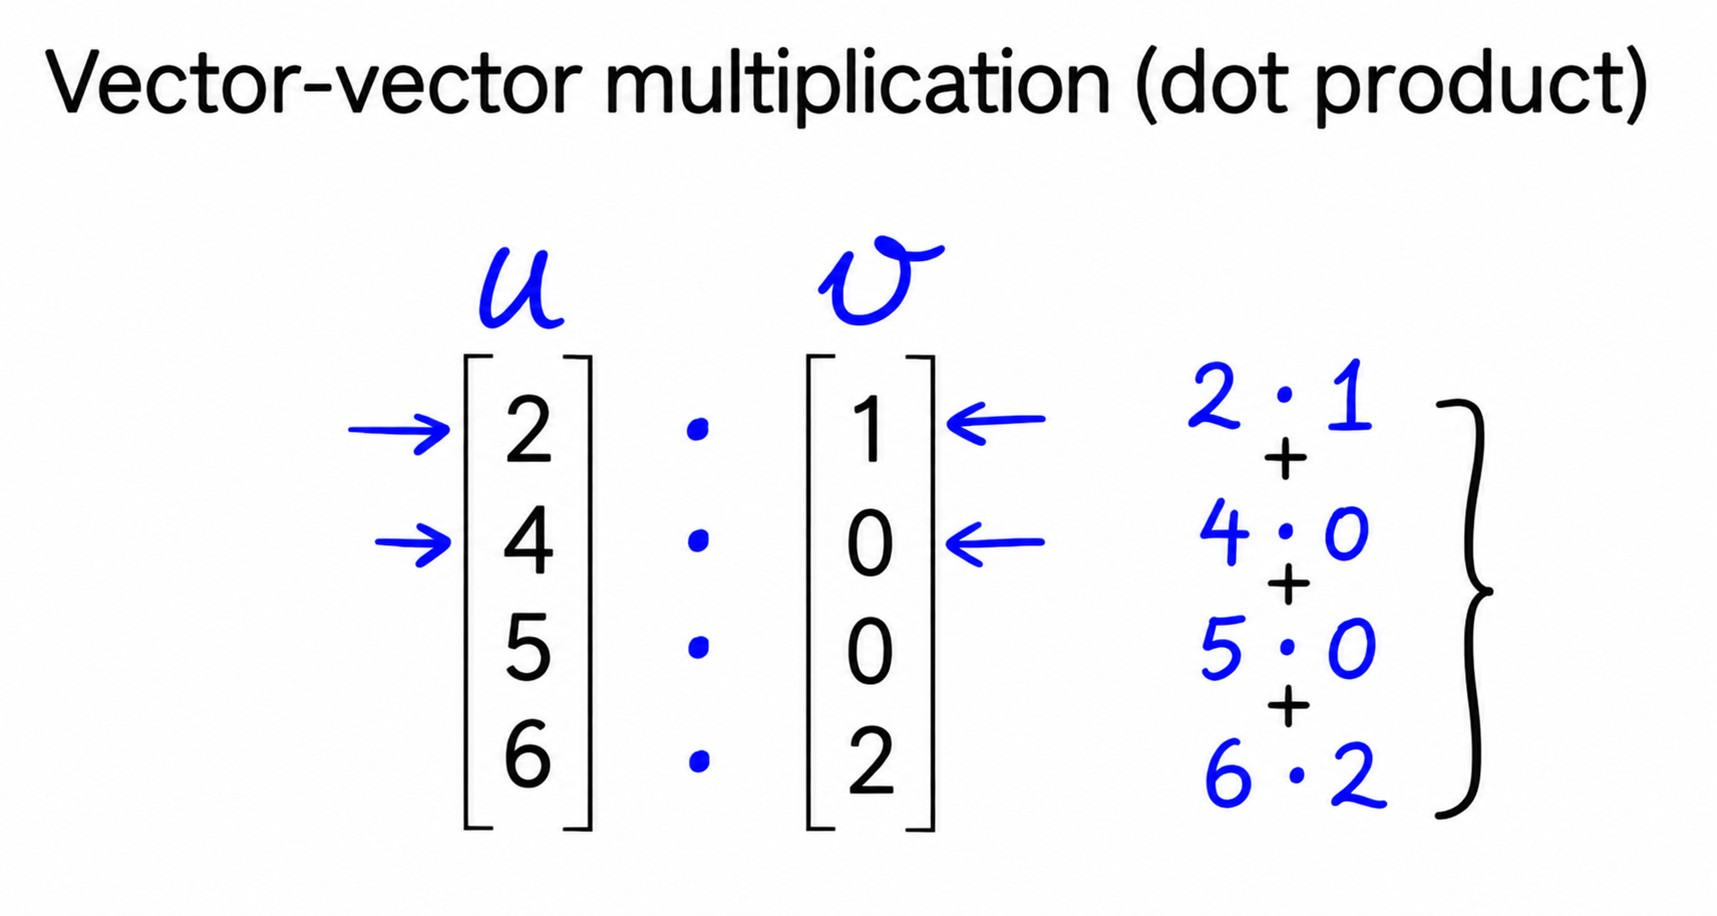

In [7]:
def vector_vector_multiplication(u, v):
    assert u.shape[0] == v.shape[0]
    
    n = u.shape[0]
    
    result = 0.0

    for i in range(n):
        result = result + u[i] * v[i]
    
    return result

In [8]:
vector_vector_multiplication(u, v)

np.float64(14.0)

In [9]:
u.dot(v)

np.int64(14)

# Matrix-vector multiplication

* Now let's say we have a matrix U (capital letter) that we want to multiply by a vector v (lowercase).

The way we do it: take the first row of the matrix U and multiply it with the vector v. This is a row - so this is exactly the situation from the dot product: a row vector times a column vector. Let's call the rows U[0], U[1] and so on, using the same notation as in NumPy.

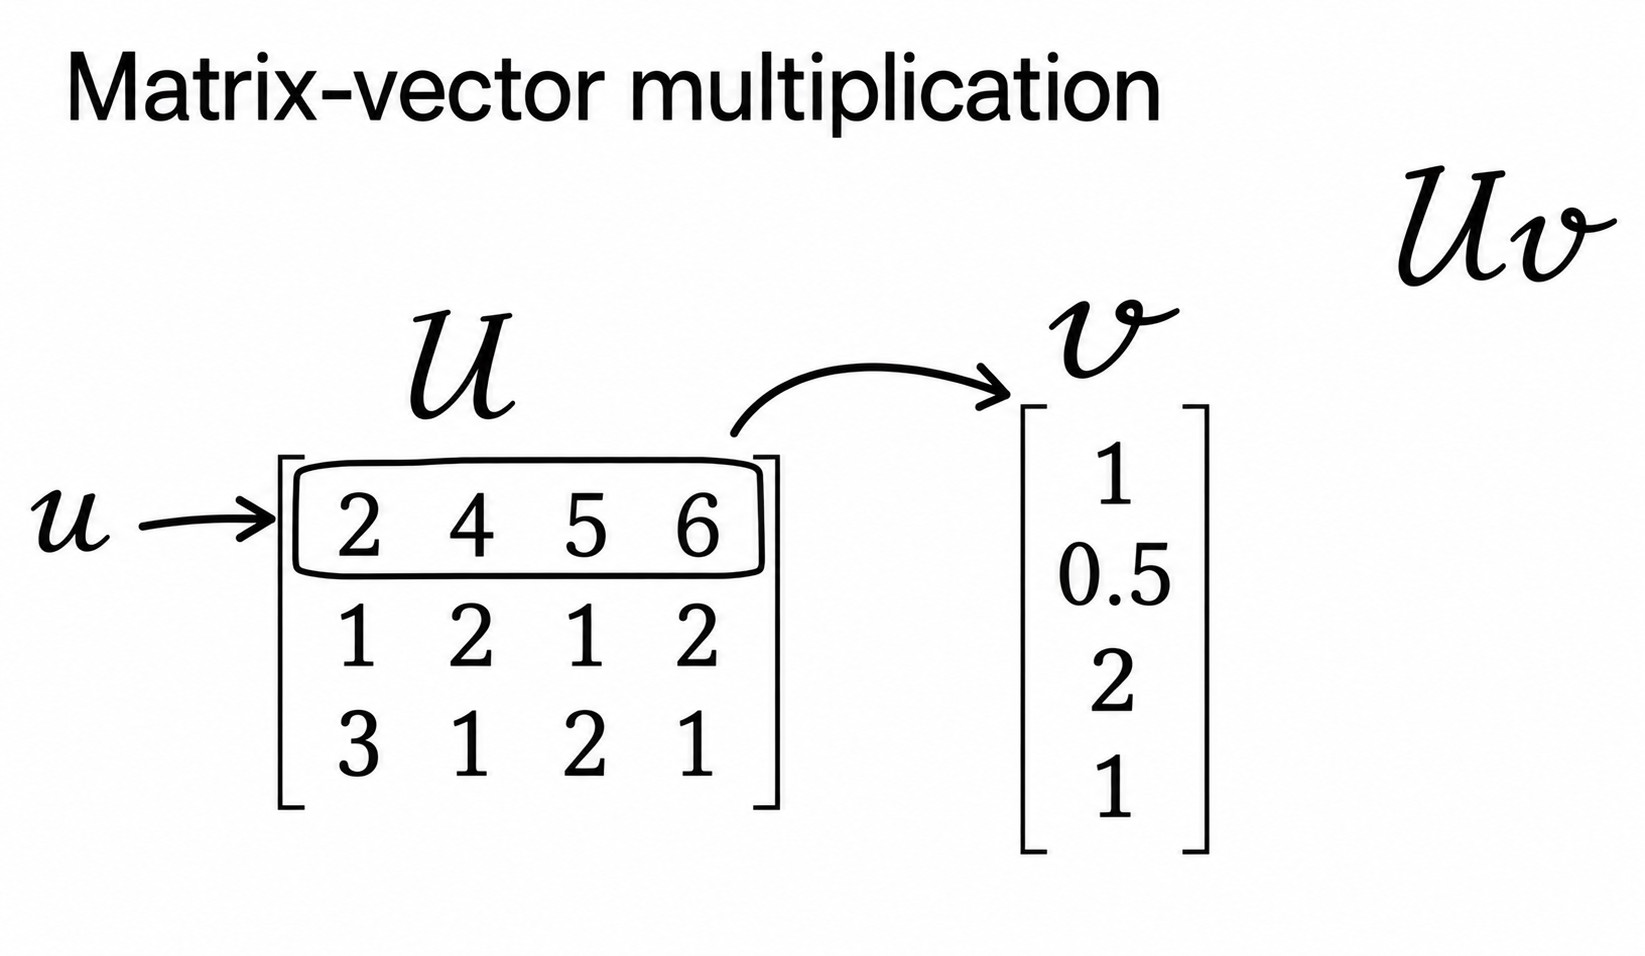

For each row of the matrix we do a vector-vector multiplication with v, and these results together are the answer. So if U has k rows - U[0] to U[k-1] - the result is k dot products, one per row. Of course the dimensionality should match: each row of U and the vector v must have the same number of elements, say n.

In [10]:
U = np.array([
[2, 4, 5, 6],
[1, 2, 1, 2],
[3, 1, 2, 1]])

In [11]:
U

array([[2, 4, 5, 6],
       [1, 2, 1, 2],
       [3, 1, 2, 1]])

In [12]:
def matrix_vector_multiplication(U, v):
    assert U.shape[1] == v.shape[0]
    
    num_rows = U.shape[0]
    
    result = np.zeros(num_rows)
    
    for i in range(num_rows):
        result[i] = vector_vector_multiplication(U[i], v)
    
    return result

First, make sure the dimensionalities match. We are interested in the number of columns of U - remember, the number of columns in U is the dimensionality of each row of U, and it should match the number of elements in v.

The number of rows of U is the dimensionality of the resulting vector: there are three rows in the matrix, so the result of the multiplication has three elements. We initialize it with zeros and then, for each row, compute the vector-vector multiplication with v and put it into the result.

In [13]:
matrix_vector_multiplication(U, v)

array([14.,  5.,  5.])

In [14]:
U.dot(v)

array([14,  5,  5])

Matrix-matrix multiplication


In [15]:
V = np.array([
[1, 1, 2],
[0, 0.5, 1], 
[0, 2, 1],
[2, 1, 0],
])

In [16]:
V

array([[1. , 1. , 2. ],
       [0. , 0.5, 1. ],
       [0. , 2. , 1. ],
       [2. , 1. , 0. ]])

In [17]:
def matrix_matrix_multiplication(U, V):
    assert U.shape[1] == V.shape[0]
    
    num_rows = U.shape[0]
    num_cols = V.shape[1]
    
    result = np.zeros((num_rows, num_cols))
    
    for i in range(num_cols):
        vi = V[:, i]
        Uvi = matrix_vector_multiplication(U, vi)
        result[:, i] = Uvi
    
    return result

### Matrix-matrix multiplication


Finally, matrix-matrix multiplication. We have a matrix U and a matrix V, and we want to compute U times V.

What we do here: take the matrix V and break it down into multiple columns - V[:, 0], V[:, 1], V[:, 2]. Then for each column of V, we multiply the entire matrix U by this column. Each such multiplication is a matrix-vector multiplication - we just learned how to do that. The results become the columns of the new matrix.

So matrix-matrix multiplication is represented as a bunch of matrix-vector multiplications. The resulting matrix has the number of rows coming from U and the number of columns coming from V.

Let's implement it. We already have U; here is V:



In [18]:
def matrix_matrix_multiplication(U, V):
    assert U.shape[1] == V.shape[0]
    
    num_rows = U.shape[0]
    num_cols = V.shape[1]
    
    result = np.zeros((num_rows, num_cols))
    
    for i in range(num_cols):
        vi = V[:, i]
        Uvi = matrix_vector_multiplication(U, vi)
        result[:, i] = Uvi
    
    return result

In [19]:
U

array([[2, 4, 5, 6],
       [1, 2, 1, 2],
       [3, 1, 2, 1]])

In [20]:
V

array([[1. , 1. , 2. ],
       [0. , 0.5, 1. ],
       [0. , 2. , 1. ],
       [2. , 1. , 0. ]])

In [21]:
matrix_matrix_multiplication(U, V)


array([[14. , 20. , 13. ],
       [ 5. ,  6. ,  5. ],
       [ 5. ,  8.5,  9. ]])

In [22]:
U.dot(V)

array([[14. , 20. , 13. ],
       [ 5. ,  6. ,  5. ],
       [ 5. ,  8.5,  9. ]])

In [24]:
I = np.eye(3)
I

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [27]:
V.dot(I)

array([[1. , 1. , 2. ],
       [0. , 0.5, 1. ],
       [0. , 2. , 1. ],
       [2. , 1. , 0. ]])

In [28]:
V

array([[1. , 1. , 2. ],
       [0. , 0.5, 1. ],
       [0. , 2. , 1. ],
       [2. , 1. , 0. ]])

### The Inverse
The inverse can only be applied in matrix that has the same number of rows as the same number 
of columns. 

In [34]:
Vs = V[[0, 1, 2]]
Vs

array([[1. , 1. , 2. ],
       [0. , 0.5, 1. ],
       [0. , 2. , 1. ]])

In [36]:
Vs_inv = np.linalg.inv(Vs)
Vs_inv

array([[ 1.        , -2.        ,  0.        ],
       [ 0.        , -0.66666667,  0.66666667],
       [ 0.        ,  1.33333333, -0.33333333]])

The identity matrix is useful for explaining what a matrix inverse is. Let's say we have a matrix A. The inverse of A, usually written A⁻¹, is a matrix such that when we multiply it by A, we get I.

In [37]:
Vs_inv.dot(Vs)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])